# 01 · Análisis exploratorio sobre datos limpios (silver y gold)

Cada gráfico responde una pregunta que se haría el jefe de turno del CCO de LATAM en Brasil y termina con una
cifra. Se usan solo datos reales (ANAC VRA + METAR de IEM) de **2023-01 a 2025-12**. Enero de 2026 queda fuera
porque se reserva para la demo, y las réplicas de `scale-test/` nunca se leen aquí.

- Salidas operadas: no canceladas, con demora conocida y sin atípicos (demora fuera de [−60, 1440] min).
- Las variables de clima y de red son las mismas que ve el modelo: lo que se sabía a T−2 h.
- Los gráficos se guardan en `docs/evidencias/eda/` y los hallazgos en `docs/evidencias/eda/hallazgos_eda.csv`.

In [1]:
import os, sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
os.environ.setdefault("LATAM_MODO", "local")      # "aws" en el clúster (lee s3a://$LAKE_BUCKET)
# Por defecto la copia local de la corrida en AWS; si no existe, la muestra versionada en el repo
_lake_aws = RAIZ / "data" / "lake_aws"
os.environ.setdefault("LATAM_LAKE_LOCAL", str(_lake_aws if _lake_aws.exists() else RAIZ / "data" / "lake_muestra"))

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pyspark.sql import functions as F
from latam_ops.comun.config import empresas_modelo, lake
from latam_ops.comun.sesion_spark import crear_sesion
from latam_ops.ml.datasets import cargar_features

spark = crear_sesion("eda")
lk = lake()
SALIDA = RAIZ / "docs" / "evidencias" / "eda"
SALIDA.mkdir(parents=True, exist_ok=True)
print("lake:", lk.base)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/12 06:15:27 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


lake: file:///app/data/lake_aws


In [2]:
# Estilo común: superficie clara, rejilla fina, una sola serie en azul y el resto en gris
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#c9c8c2"
TINTA, TINTA2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e7e6e1", "#fcfcfb"
FUENTE = "Fuente: ANAC, Voo Regular Ativo (VRA) y METAR de Iowa Environmental Mesonet, 2023–2025. Elaboración propia."
matplotlib.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "figure.dpi": 110,
})
hallazgos = []


def lienzo(ancho=9.5, alto=5.0, izq=0.09):
    fig, ax = plt.subplots(figsize=(ancho, alto))
    fig.subplots_adjust(top=0.79, bottom=0.17, left=izq, right=0.97)
    return fig, ax


def cerrar(fig, ax, nombre, pregunta, conclusion, implicancia):
    """Título = pregunta, subtítulo = respuesta con cifra; guarda PNG y registra el hallazgo."""
    fig.text(0.02, 0.95, pregunta, fontsize=13, fontweight="bold", color=TINTA, va="top")
    fig.text(0.02, 0.885, conclusion, fontsize=10, color=TINTA2, va="top", linespacing=1.4)
    fig.text(0.02, 0.02, FUENTE, fontsize=7.5, color=TINTA2)
    fig.savefig(SALIDA / f"{nombre}.png", dpi=170)
    plt.show()
    hallazgos.append({"figura": f"docs/evidencias/eda/{nombre}.png", "pregunta": pregunta,
                      "hallazgo": conclusion, "implicancia_operativa": implicancia})


def pct(x, d=1):
    return f"{x * 100:.{d}f} %".replace(".", ",")


def miles(n):
    return f"{int(n):,}".replace(",", " ")

In [3]:
vuelos_all = spark.read.parquet(lk.ruta("silver_vuelos")).where("year BETWEEN 2023 AND 2025")
# Solo las empresas de pasajeros del grupo (config/aerolineas_latam.yaml); LATAM Cargo queda fuera, igual que en el modelo
vuelos = vuelos_all.where(F.col("es_latam") & F.col("empresa_icao").isin(empresas_modelo()))
operados = vuelos.where("NOT cancelado AND NOT es_atipico AND demora_salida_min IS NOT NULL")
feats = cargar_features(spark, lk).where("year BETWEEN 2023 AND 2025")
vuelos.cache(); feats.cache()
n_prog, n_oper, n_feat = vuelos.count(), operados.count(), feats.count()
print(f"Vuelos LATAM programados: {miles(n_prog)} | operados válidos: {miles(n_oper)} | filas de modelado (gold): {miles(n_feat)}")
print("Todas las aerolíneas en VRA 2023–2025:", miles(vuelos_all.count()))
vuelos.groupBy("empresa_icao").count().orderBy(F.desc("count")).show()

26/11/12 06:15:31 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Vuelos LATAM programados: 845 816 | operados válidos: 832 186 | filas de modelado (gold): 832 186
Todas las aerolíneas en VRA 2023–2025: 2 879 793


+------------+------+
|empresa_icao| count|
+------------+------+
|         TAM|807215|
|         LAN| 25955|
|         LPE|  6381|
|         LAP|  3962|
|         ARE|  1660|
|         LNE|   643|
+------------+------+



## G1. ¿Cuál es la línea base y está mejorando o empeorando?

           t15       t60       n
year                            
2023  0.181920  0.024251  262131
2024  0.171459  0.024463  271470
2025  0.189614  0.025407  298585


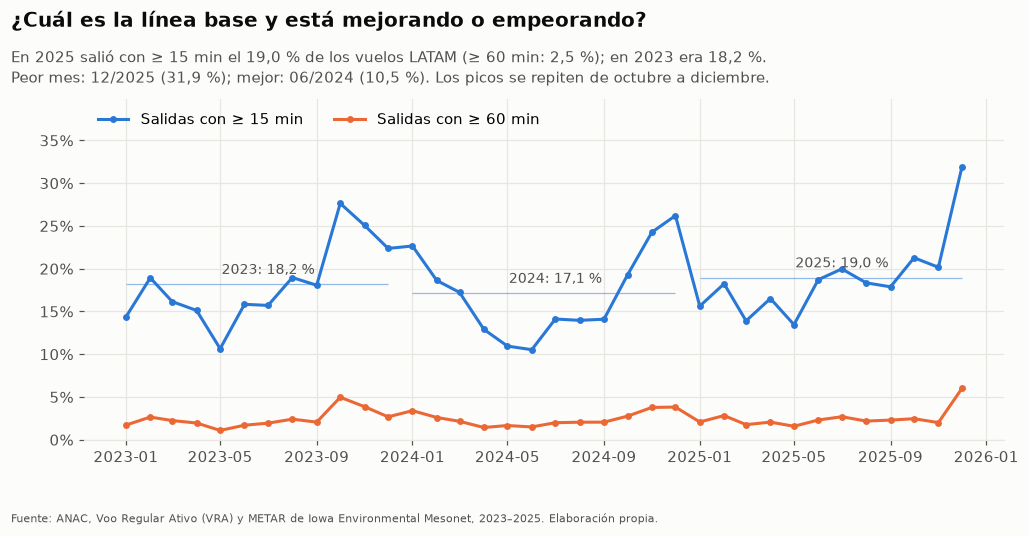

In [4]:
g1 = (operados.groupBy("year", "month")
      .agg(F.avg(F.col("y_demora15").cast("double")).alias("t15"), F.avg(F.col("y_demora60").cast("double")).alias("t60"),
           F.count("*").alias("n"))
      .orderBy("year", "month").toPandas())
g1["fecha"] = pd.to_datetime(dict(year=g1.year, month=g1.month, day=1))
anual = (operados.groupBy("year").agg(F.avg(F.col("y_demora15").cast("double")).alias("t15"),
                                       F.avg(F.col("y_demora60").cast("double")).alias("t60"), F.count("*").alias("n"))
         .orderBy("year").toPandas().set_index("year"))
print(anual)
fig, ax = lienzo()
ax.plot(g1.fecha, g1.t15, color=AZUL, lw=2, marker="o", ms=3.5, label="Salidas con ≥ 15 min")
ax.plot(g1.fecha, g1.t60, color=NARANJA, lw=2, marker="o", ms=3.5, label="Salidas con ≥ 60 min")
for y, r in anual.iterrows():
    medio = pd.Timestamp(year=int(y), month=7, day=1)
    ax.hlines(r.t15, pd.Timestamp(year=int(y), month=1, day=1), pd.Timestamp(year=int(y), month=12, day=1),
              color=AZUL, lw=0.8, alpha=0.5)
    ax.text(medio, r.t15 + 0.012, f"{int(y)}: {pct(r.t15)}", ha="center", color=TINTA2, fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, max(g1.t15) * 1.25)
ax.legend(loc="upper left", frameon=False, ncol=2)
peor = g1.loc[g1.t15.idxmax()]
mejor = g1.loc[g1.t15.idxmin()]
t15_25, t60_25 = anual.loc[2025, "t15"], anual.loc[2025, "t60"]
cerrar(fig, ax, "g1_linea_base_mensual",
       "¿Cuál es la línea base y está mejorando o empeorando?",
       f"En 2025 salió con ≥ 15 min el {pct(t15_25)} de los vuelos LATAM (≥ 60 min: {pct(t60_25)}); "
       f"en 2023 era {pct(anual.loc[2023, 't15'])}.\nPeor mes: {peor.fecha:%m/%Y} ({pct(peor.t15)}); "
       f"mejor: {mejor.fecha:%m/%Y} ({pct(mejor.t15)}). Los picos se repiten de octubre a diciembre.",
       "La línea base de salida es la vara con la que se mide la alerta; la variación mensual obliga a vigilar "
       "el KPI K1 cada mes y no solo el promedio anual.")

## G2. ¿LATAM sale peor o mejor que sus competidores en Brasil?

grupo     LATAM      Azul       Gol
year                               
2023   0.181920  0.137299  0.209092
2024   0.171459  0.168934  0.158077
2025   0.189614  0.147088  0.136687


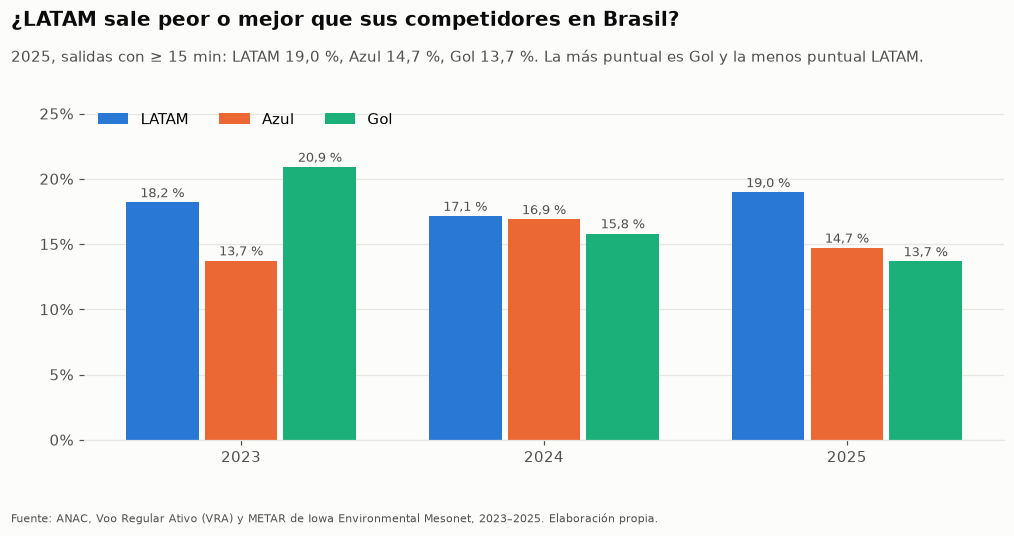

In [5]:
grupos = (F.when(F.col("es_latam") & F.col("empresa_icao").isin(empresas_modelo()), "LATAM").when(F.col("empresa_icao") == "AZU", "Azul")
          .when(F.col("empresa_icao") == "GLO", "Gol").otherwise(None))
comp = (vuelos_all.where("NOT cancelado AND NOT es_atipico AND demora_salida_min IS NOT NULL")
        .withColumn("grupo", grupos).where("grupo IS NOT NULL")
        .groupBy("year", "grupo").agg(F.avg(F.col("y_demora15").cast("double")).alias("t15"), F.count("*").alias("n"))
        .toPandas().pivot(index="year", columns="grupo", values="t15")[["LATAM", "Azul", "Gol"]])
print(comp)
fig, ax = lienzo()
anchos, x = 0.26, range(len(comp))
for i, (g, c) in enumerate(zip(["LATAM", "Azul", "Gol"], [AZUL, NARANJA, AQUA])):
    xs = [k + (i - 1) * anchos for k in x]
    ax.bar(xs, comp[g], width=anchos - 0.02, color=c, label=g)
    for xi, v in zip(xs, comp[g]):
        ax.text(xi, v + 0.004, pct(v), ha="center", fontsize=8.5, color=TINTA2)
ax.set_xticks(list(x), [str(a) for a in comp.index]); ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.set_ylim(0, comp.values.max() * 1.25)
r25 = comp.loc[2025]
orden = r25.sort_values()
cerrar(fig, ax, "g2_latam_vs_competencia",
       "¿LATAM sale peor o mejor que sus competidores en Brasil?",
       f"2025, salidas con ≥ 15 min: LATAM {pct(r25.LATAM)}, Azul {pct(r25.Azul)}, Gol {pct(r25.Gol)}. "
       f"La más puntual es {orden.index[0]} y la menos puntual {orden.index[-1]}.",
       "Sitúa la línea base de LATAM frente al mercado brasileño con la misma fuente y la misma regla de medición.")

## G3. ¿Qué aeropuertos concentran las salidas demoradas?

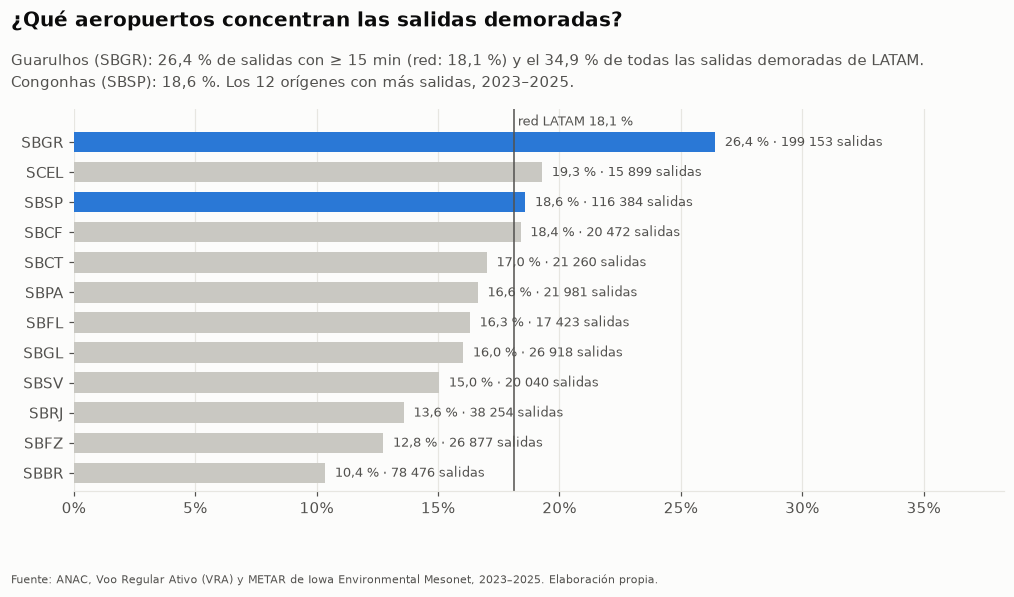

In [6]:
g3 = (operados.groupBy("origen_icao").agg(F.count("*").alias("n"), F.avg(F.col("y_demora15").cast("double")).alias("t15"),
                                           F.sum("y_demora15").alias("dem"))
      .orderBy(F.desc("n")).limit(12).toPandas())
total_dem = operados.agg(F.sum("y_demora15")).first()[0]
media_red = operados.agg(F.avg(F.col("y_demora15").cast("double"))).first()[0]
g3 = g3.sort_values("t15")
fig, ax = lienzo(9.5, 5.6, izq=0.08)
colores = [AZUL if a in ("SBGR", "SBSP") else GRIS for a in g3.origen_icao]
ax.barh(g3.origen_icao, g3.t15, color=colores, height=0.68)
for yi, (t, n) in enumerate(zip(g3.t15, g3.n)):
    ax.text(t + 0.004, yi, f"{pct(t)} · {miles(n)} salidas", va="center", fontsize=8.5, color=TINTA2)
ax.axvline(media_red, color=TINTA2, lw=1)
ax.set_ylim(-0.6, len(g3) + 0.1)
ax.text(media_red, len(g3) - 0.45, f" red LATAM {pct(media_red)}", fontsize=8.5, color=TINTA2)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0)); ax.grid(axis="y", visible=False)
ax.set_xlim(0, g3.t15.max() * 1.45)
gru = g3.set_index("origen_icao").loc["SBGR"]
cgh = g3.set_index("origen_icao").loc["SBSP"]
cuota = gru.dem / total_dem
cerrar(fig, ax, "g3_aeropuertos",
       "¿Qué aeropuertos concentran las salidas demoradas?",
       f"Guarulhos (SBGR): {pct(gru.t15)} de salidas con ≥ 15 min (red: {pct(media_red)}) y el {pct(cuota)} de todas las "
       f"salidas demoradas de LATAM.\nCongonhas (SBSP): {pct(cgh.t15)}. Los 12 orígenes con más salidas, 2023–2025.",
       "La alerta se despliega primero en el CCO de SBGR, donde está casi un tercio del problema.")

## G4. ¿En qué hora del día se concentra el riesgo?

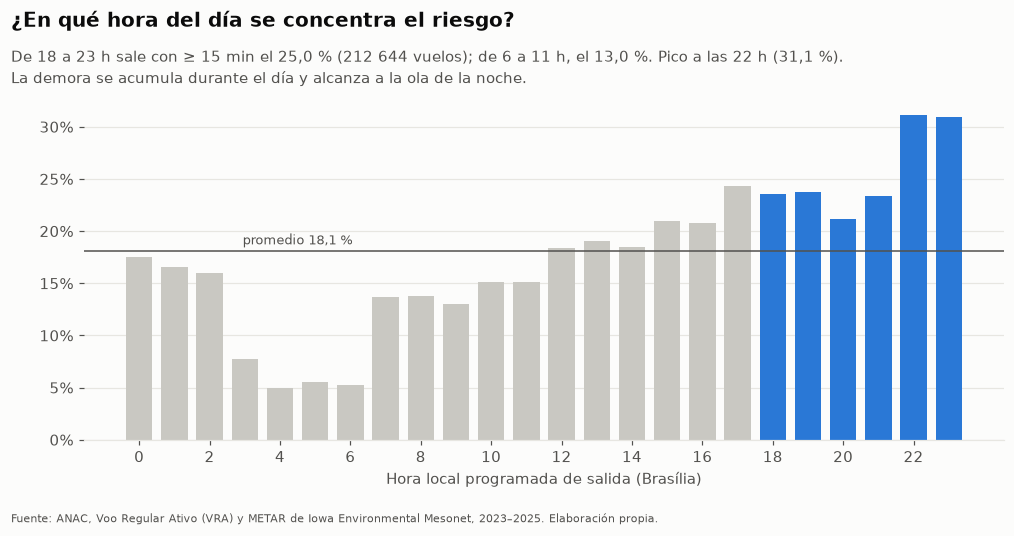

In [7]:
g4 = (feats.groupBy("hora_local").agg(F.avg(F.col("y_demora15").cast("double")).alias("t15"), F.count("*").alias("n"))
      .orderBy("hora_local").toPandas())
media_f = feats.agg(F.avg(F.col("y_demora15").cast("double"))).first()[0]
noche = feats.where("hora_local >= 18").agg(F.avg(F.col("y_demora15").cast("double")), F.count("*")).first()
manana = feats.where("hora_local BETWEEN 6 AND 11").agg(F.avg(F.col("y_demora15").cast("double"))).first()[0]
fig, ax = lienzo()
ax.bar(g4.hora_local, g4.t15, color=[AZUL if h >= 18 else GRIS for h in g4.hora_local], width=0.75)
ax.axhline(media_f, color=TINTA2, lw=1)
ax.text(4.5, media_f + 0.006, f"promedio {pct(media_f)}", ha="center", fontsize=8.5, color=TINTA2)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hora local programada de salida (Brasília)")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0)); ax.grid(axis="x", visible=False)
pico = g4.loc[g4[g4.n >= 1000].t15.idxmax()]
cerrar(fig, ax, "g4_hora_del_dia",
       "¿En qué hora del día se concentra el riesgo?",
       f"De 18 a 23 h sale con ≥ 15 min el {pct(noche[0])} ({miles(noche[1])} vuelos); de 6 a 11 h, el {pct(manana)}. "
       f"Pico a las {int(pico.hora_local)} h ({pct(pico.t15)}).\nLa demora se acumula durante el día y alcanza a la ola de la noche.",
       "Reforzar la holgura de giro y la dotación del CCO en el turno de tarde-noche; la primera ola de la mañana "
       "casi no necesita alerta.")

## G5. ¿El clima reportado en el METAR a T−2 h anticipa la demora?

                    clima       t15       t60       n
3               Sin METAR  0.149612  0.040531   17024
4  VFR/MVFR sin fenómenos  0.174073  0.022569  703406
5     IFR/LIFR sin niebla  0.196701  0.026110   65836
0             Niebla (FG)  0.253446  0.057044    5224
1             Lluvia (RA)  0.261086  0.040561   22460
2           Tormenta (TS)  0.313665  0.059827   18236


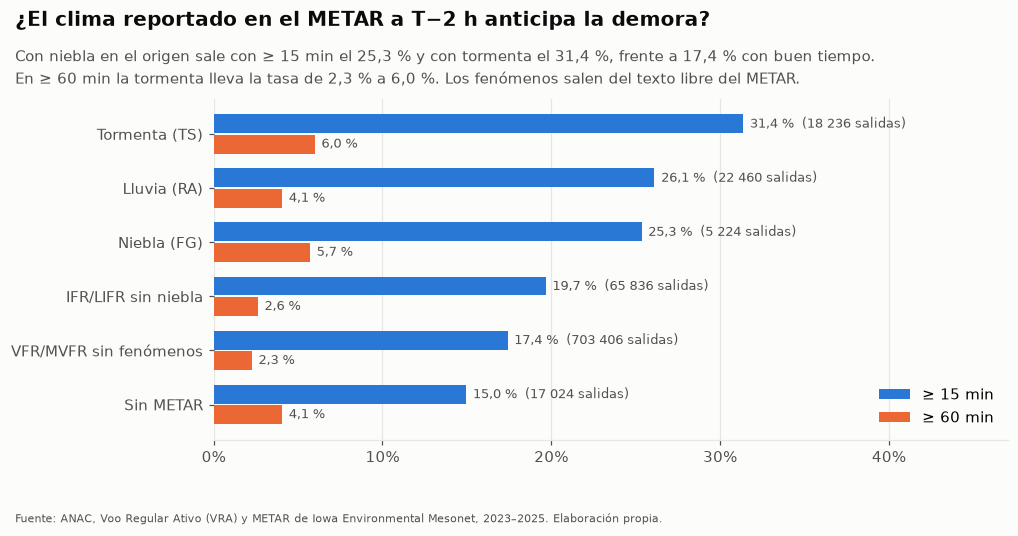

In [8]:
clima = (F.when(F.col("o_fen_tormenta") == 1, "Tormenta (TS)").when(F.col("o_fen_niebla") == 1, "Niebla (FG)")
         .when(F.col("o_categoria_vuelo").isin("IFR", "LIFR"), "IFR/LIFR sin niebla")
         .when(F.col("o_fen_lluvia") == 1, "Lluvia (RA)").when(F.col("o_categoria_vuelo").isNull(), "Sin METAR")
         .otherwise("VFR/MVFR sin fenómenos"))
g5 = (feats.withColumn("clima", clima).groupBy("clima")
      .agg(F.avg(F.col("y_demora15").cast("double")).alias("t15"), F.avg(F.col("y_demora60").cast("double")).alias("t60"),
           F.count("*").alias("n")).toPandas().sort_values("t15"))
print(g5)
fig, ax = lienzo(9.5, 5.0, izq=0.21)
y = range(len(g5)); h = 0.38
ax.barh([k + h / 2 for k in y], g5.t15, height=h - 0.03, color=AZUL, label="≥ 15 min")
ax.barh([k - h / 2 for k in y], g5.t60, height=h - 0.03, color=NARANJA, label="≥ 60 min")
for k, (t, t6, n) in enumerate(zip(g5.t15, g5.t60, g5.n)):
    ax.text(t + 0.004, k + h / 2, f"{pct(t)}  ({miles(n)} salidas)", va="center", fontsize=8.5, color=TINTA2)
    ax.text(t6 + 0.004, k - h / 2, pct(t6), va="center", fontsize=8.5, color=TINTA2)
ax.set_yticks(list(y), g5.clima); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0)); ax.set_xlim(0, g5.t15.max() * 1.5)
ax.legend(frameon=False, loc="lower right")
s = g5.set_index("clima")
base = s.loc["VFR/MVFR sin fenómenos"]
cerrar(fig, ax, "g5_clima_metar",
       "¿El clima reportado en el METAR a T−2 h anticipa la demora?",
       f"Con niebla en el origen sale con ≥ 15 min el {pct(s.loc['Niebla (FG)'].t15)} y con tormenta el "
       f"{pct(s.loc['Tormenta (TS)'].t15)}, frente a {pct(base.t15)} con buen tiempo.\n"
       f"En ≥ 60 min la tormenta lleva la tasa de {pct(base.t60)} a {pct(s.loc['Tormenta (TS)'].t60)}. "
       "Los fenómenos salen del texto libre del METAR.",
       "Protocolo de clima en el CCO: un METAR con TS o FG a T−2 h sube el vuelo en la lista de revisión; "
       "son pocos casos al año, así que el costo de revisarlos es bajo.")

## G6. ¿Cuando la red ya viene atrasada en el origen, el vuelo también se atrasa? (propagación)

                     red       t15       n             etiqueta
0  0 sin salidas previas  0.119868  128500  sin salidas previas
1                1 <10 %  0.126414  319578                <10 %
2              2 10–30 %  0.209458  231388              10–30 %
3              3 30–50 %  0.297679   87134              30–50 %
4                4 ≥50 %  0.314747   65586                ≥50 %


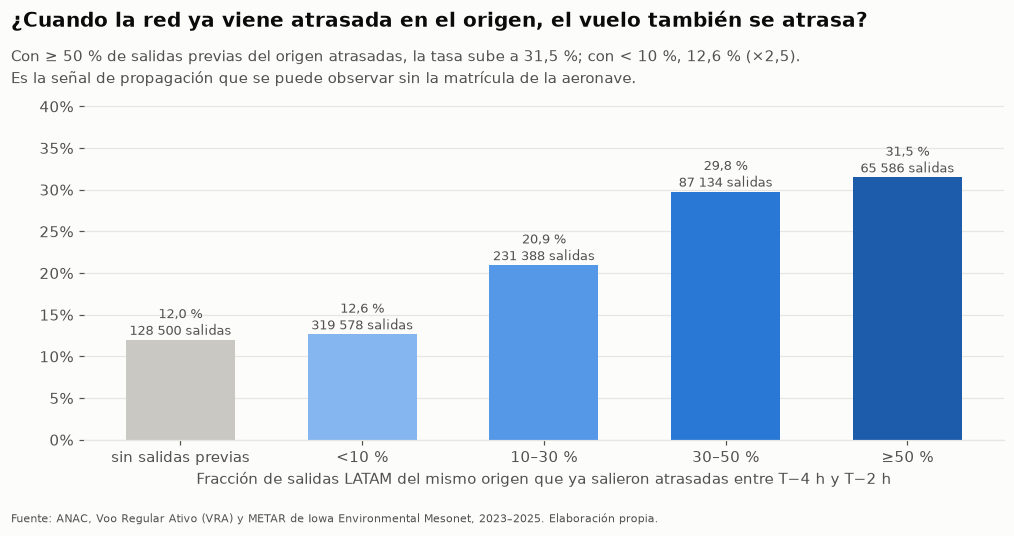

In [9]:
red = (F.when(F.col("red_frac_atrasadas").isNull(), "0 sin salidas previas")
       .when(F.col("red_frac_atrasadas") < 0.1, "1 <10 %").when(F.col("red_frac_atrasadas") < 0.3, "2 10–30 %")
       .when(F.col("red_frac_atrasadas") < 0.5, "3 30–50 %").otherwise("4 ≥50 %"))
g6 = (feats.withColumn("red", red).groupBy("red")
      .agg(F.avg(F.col("y_demora15").cast("double")).alias("t15"), F.count("*").alias("n")).orderBy("red").toPandas())
g6["etiqueta"] = g6.red.str[2:]
print(g6)
fig, ax = lienzo()
ramp = ["#c9c8c2", "#86b6ef", "#5598e7", "#2a78d6", "#1c5cab"]   # ordinal: más atraso previo = más oscuro
ax.bar(g6.etiqueta, g6.t15, color=ramp[:len(g6)], width=0.6)
for k, (t, n) in enumerate(zip(g6.t15, g6.n)):
    ax.text(k, t + 0.006, f"{pct(t)}\n{miles(n)} salidas", ha="center", fontsize=8.5, color=TINTA2)
ax.set_xlabel("Fracción de salidas LATAM del mismo origen que ya salieron atrasadas entre T−4 h y T−2 h")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0)); ax.grid(axis="x", visible=False)
ax.set_ylim(0, g6.t15.max() * 1.3)
r = g6.set_index("etiqueta")
cerrar(fig, ax, "g6_propagacion_red",
       "¿Cuando la red ya viene atrasada en el origen, el vuelo también se atrasa?",
       f"Con ≥ 50 % de salidas previas del origen atrasadas, la tasa sube a {pct(r.loc['≥50 %'].t15)}; con < 10 %, "
       f"{pct(r.loc['<10 %'].t15)} (×{str(round(r.loc['≥50 %'].t15 / r.loc['<10 %'].t15, 1)).replace('.', ',')}).\n" +
       "Es la señal de propagación que se puede observar sin la matrícula de la aeronave.",
       "Alerta de red: si en [T−4 h, T−2 h) más del 30 % de las salidas del hub van atrasadas, escalar al "
       "coordinador del hub antes de que la demora alcance a la ola siguiente.")

## G7. ¿La demora del mismo vuelo el día anterior predice la de hoy?

                 prev       t15       n          etiqueta
0  0 sin dato de ayer  0.178486  114653  sin dato de ayer
1  1 ayer salió antes  0.116872  354797  ayer salió antes
2     2 ayer 0–14 min  0.208634  233222     ayer 0–14 min
3    3 ayer 15–59 min  0.307714  112299    ayer 15–59 min
4     4 ayer ≥ 60 min  0.331397   17215     ayer ≥ 60 min


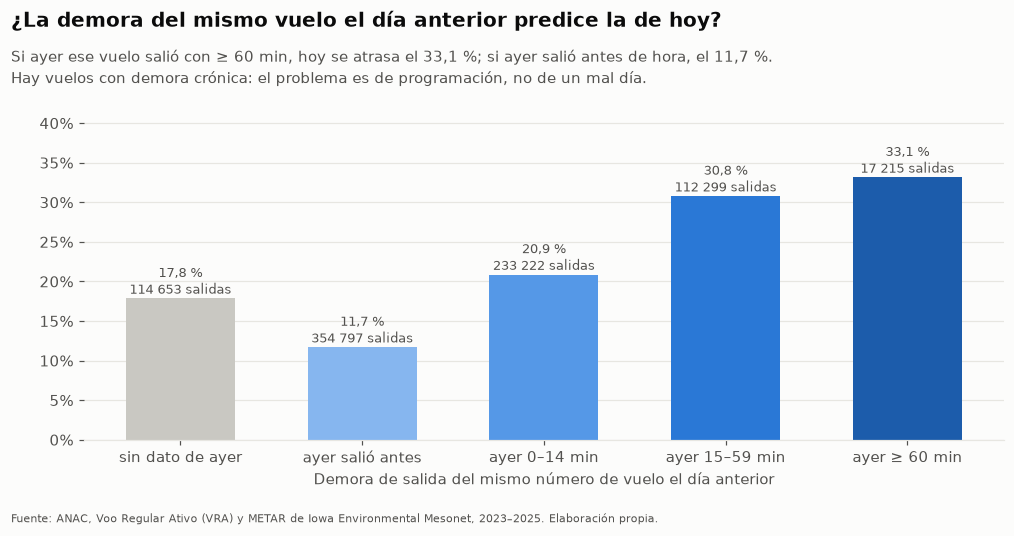

In [10]:
prev = (F.when(F.col("prev_dia_demora").isNull(), "0 sin dato de ayer")
        .when(F.col("prev_dia_demora") < 0, "1 ayer salió antes").when(F.col("prev_dia_demora") < 15, "2 ayer 0–14 min")
        .when(F.col("prev_dia_demora") < 60, "3 ayer 15–59 min").otherwise("4 ayer ≥ 60 min"))
g7 = (feats.withColumn("prev", prev).groupBy("prev")
      .agg(F.avg(F.col("y_demora15").cast("double")).alias("t15"), F.count("*").alias("n")).orderBy("prev").toPandas())
g7["etiqueta"] = g7.prev.str[2:]
print(g7)
fig, ax = lienzo()
ax.bar(g7.etiqueta, g7.t15, color=["#c9c8c2", "#86b6ef", "#5598e7", "#2a78d6", "#1c5cab"][:len(g7)], width=0.6)
for k, (t, n) in enumerate(zip(g7.t15, g7.n)):
    ax.text(k, t + 0.006, f"{pct(t)}\n{miles(n)} salidas", ha="center", fontsize=8.5, color=TINTA2)
ax.set_xlabel("Demora de salida del mismo número de vuelo el día anterior")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0)); ax.grid(axis="x", visible=False)
ax.set_ylim(0, g7.t15.max() * 1.3)
r = g7.set_index("etiqueta")
cerrar(fig, ax, "g7_demora_dia_anterior",
       "¿La demora del mismo vuelo el día anterior predice la de hoy?",
       f"Si ayer ese vuelo salió con ≥ 60 min, hoy se atrasa el {pct(r.loc['ayer ≥ 60 min'].t15)}; "
       f"si ayer salió antes de hora, el {pct(r.loc['ayer salió antes'].t15)}.\n"
       "Hay vuelos con demora crónica: el problema es de programación, no de un mal día.",
       "Planeamiento de red revisa cada mes los números de vuelo con demora repetida y ajusta su horario o su "
       "tiempo de giro; la alerta diaria no lo resuelve sola.")

## G8. ¿Cuántos vuelos se cancelan y cuándo?

            tc  canc
year                
2023  0.016862  4496
2024  0.015360  4235
2025  0.016034  4866


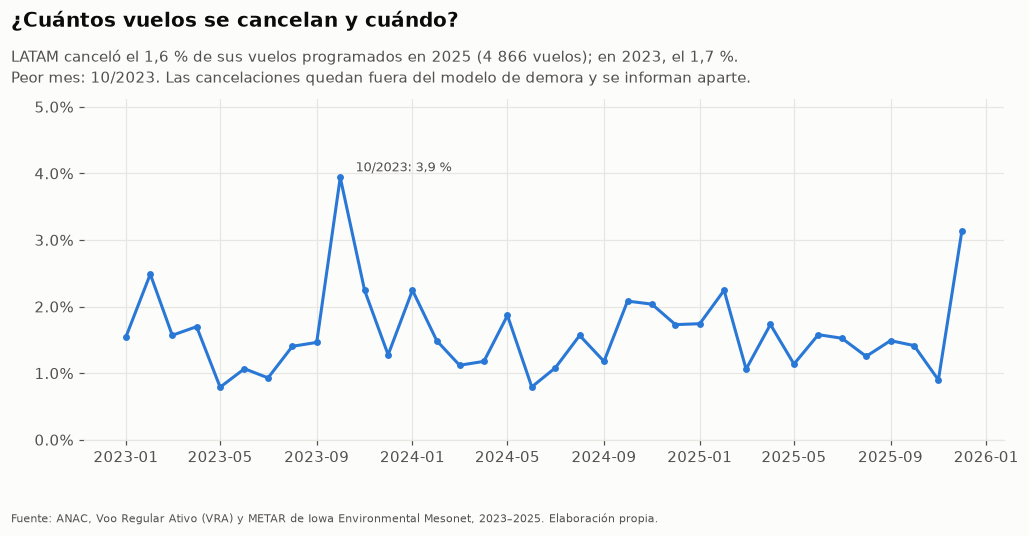

In [11]:
g8 = (vuelos.groupBy("year", "month").agg(F.avg(F.col("cancelado").cast("double")).alias("tc"), F.count("*").alias("n"),
                                           F.sum(F.col("cancelado").cast("int")).alias("canc"))
      .orderBy("year", "month").toPandas())
g8["fecha"] = pd.to_datetime(dict(year=g8.year, month=g8.month, day=1))
anual_c = vuelos.groupBy("year").agg(F.avg(F.col("cancelado").cast("double")).alias("tc"),
                                      F.sum(F.col("cancelado").cast("int")).alias("canc")).orderBy("year").toPandas().set_index("year")
print(anual_c)
fig, ax = lienzo()
ax.plot(g8.fecha, g8.tc, color=AZUL, lw=2, marker="o", ms=3.5)
pico = g8.loc[g8.tc.idxmax()]
ax.annotate(f"{pico.fecha:%m/%Y}: {pct(pico.tc)}", (pico.fecha, pico.tc), xytext=(10, 4), textcoords="offset points",
            fontsize=8.5, color=TINTA2)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1)); ax.set_ylim(0, g8.tc.max() * 1.3)
cerrar(fig, ax, "g8_cancelaciones",
       "¿Cuántos vuelos se cancelan y cuándo?",
       f"LATAM canceló el {pct(anual_c.loc[2025, 'tc'])} de sus vuelos programados en 2025 "
       f"({miles(anual_c.loc[2025, 'canc'])} vuelos); en 2023, el {pct(anual_c.loc[2023, 'tc'])}.\nPeor mes: {pico.fecha:%m/%Y}. Las cancelaciones quedan fuera del modelo de demora y se informan aparte.",
       "La alerta cubre demoras, no cancelaciones; un vuelo cancelado no entra en el cálculo de precisión ni de valor.")

## Resumen de hallazgos

In [12]:
tabla = pd.DataFrame(hallazgos)[["pregunta", "hallazgo", "implicancia_operativa", "figura"]]
tabla["hallazgo"] = tabla.hallazgo.str.replace("\n", " ", regex=False)
tabla.to_csv(SALIDA / "hallazgos_eda.csv", index=False)
pd.set_option("display.max_colwidth", 200)
tabla

,pregunta,hallazgo,implicancia_operativa,figura
0,¿Cuál es la línea base y está mejorando o empeorando?,"En 2025 salió con ≥ 15 min el 19,0 % de los vuelos LATAM (≥ 60 min: 2,5 %); en 2023 era 18,2 %. Peor mes: 12/2025 (31,9 %); mejor: 06/2024 (10,5 %). Los picos se repiten de octubre a diciembre.",La línea base de salida es la vara con la que se mide la alerta; la variación mensual obliga a vigilar el KPI K1 cada mes y no solo el promedio anual.,docs/evidencias/eda/g1_linea_base_mensual.png
1,¿LATAM sale peor o mejor que sus competidores en Brasil?,"2025, salidas con ≥ 15 min: LATAM 19,0 %, Azul 14,7 %, Gol 13,7 %. La más puntual es Gol y la menos puntual LATAM.",Sitúa la línea base de LATAM frente al mercado brasileño con la misma fuente y la misma regla de medición.,docs/evidencias/eda/g2_latam_vs_competencia.png
2,¿Qué aeropuertos concentran las salidas demoradas?,"Guarulhos (SBGR): 26,4 % de salidas con ≥ 15 min (red: 18,1 %) y el 34,9 % de todas las salidas demoradas de LATAM. Congonhas (SBSP): 18,6 %. Los 12 orígenes con más salidas, 2023–2025.","La alerta se despliega primero en el CCO de SBGR, donde está casi un tercio del problema.",docs/evidencias/eda/g3_aeropuertos.png
3,¿En qué hora del día se concentra el riesgo?,"De 18 a 23 h sale con ≥ 15 min el 25,0 % (212 644 vuelos); de 6 a 11 h, el 13,0 %. Pico a las 22 h (31,1 %). La demora se acumula durante el día y alcanza a la ola de la noche.",Reforzar la holgura de giro y la dotación del CCO en el turno de tarde-noche; la primera ola de la mañana casi no necesita alerta.,docs/evidencias/eda/g4_hora_del_dia.png
4,¿El clima reportado en el METAR a T−2 h anticipa la demora?,"Con niebla en el origen sale con ≥ 15 min el 25,3 % y con tormenta el 31,4 %, frente a 17,4 % con buen tiempo. En ≥ 60 min la tormenta lleva la tasa de 2,3 % a 6,0 %. Los fenómenos salen del texto...","Protocolo de clima en el CCO: un METAR con TS o FG a T−2 h sube el vuelo en la lista de revisión; son pocos casos al año, así que el costo de revisarlos es bajo.",docs/evidencias/eda/g5_clima_metar.png
5,"¿Cuando la red ya viene atrasada en el origen, el vuelo también se atrasa?","Con ≥ 50 % de salidas previas del origen atrasadas, la tasa sube a 31,5 %; con < 10 %, 12,6 % (×2,5). Es la señal de propagación que se puede observar sin la matrícula de la aeronave.","Alerta de red: si en [T−4 h, T−2 h) más del 30 % de las salidas del hub van atrasadas, escalar al coordinador del hub antes de que la demora alcance a la ola siguiente.",docs/evidencias/eda/g6_propagacion_red.png
6,¿La demora del mismo vuelo el día anterior predice la de hoy?,"Si ayer ese vuelo salió con ≥ 60 min, hoy se atrasa el 33,1 %; si ayer salió antes de hora, el 11,7 %. Hay vuelos con demora crónica: el problema es de programación, no de un mal día.",Planeamiento de red revisa cada mes los números de vuelo con demora repetida y ajusta su horario o su tiempo de giro; la alerta diaria no lo resuelve sola.,docs/evidencias/eda/g7_demora_dia_anterior.png
7,¿Cuántos vuelos se cancelan y cuándo?,"LATAM canceló el 1,6 % de sus vuelos programados en 2025 (4 866 vuelos); en 2023, el 1,7 %. Peor mes: 10/2023. Las cancelaciones quedan fuera del modelo de demora y se informan aparte.","La alerta cubre demoras, no cancelaciones; un vuelo cancelado no entra en el cálculo de precisión ni de valor.",docs/evidencias/eda/g8_cancelaciones.png


## Control: ¿coinciden estas cifras con las del módulo de valor?

`ml/valor_negocio.py` calcula sus hallazgos solo sobre el **test 2025** (vuelos con predicción). Aquí se repite el
mismo cálculo con el mismo filtro y se compara con `docs/evidencias/valor/hallazgos_*.csv`. Las cifras de los
gráficos de arriba son de 2023–2025 y por eso difieren un poco; lo que importa es que el orden y el tamaño del
efecto se mantienen.

In [13]:
from latam_ops.ml.valor_negocio import hallazgos as hallazgos_valor
pred = spark.read.parquet(lk.ruta("gold_predicciones")).select("id_vuelo").distinct()
test = feats.where("split = 'test'").join(pred, "id_vuelo")
mios = hallazgos_valor(test)
filas = []
for k in ("aeropuertos", "franjas", "clima", "red"):
    archivo = RAIZ / "docs" / "evidencias" / "valor" / f"hallazgos_{k}.csv"
    if not archivo.exists():
        continue
    ref = pd.read_csv(archivo).set_index("grupo")
    for f in mios[k]:
        if f["grupo"] in ref.index:
            r = ref.loc[f["grupo"]]
            filas.append({"tabla": k, "grupo": f["grupo"], "vuelos_eda": f["vuelos"], "vuelos_valor": int(r.vuelos),
                          "tasa_eda": f["tasa_demora15"], "tasa_valor": float(r.tasa_demora15),
                          "coincide": f["vuelos"] == int(r.vuelos) and abs(f["tasa_demora15"] - r.tasa_demora15) < 1e-3})
control = pd.DataFrame(filas)
control.to_csv(SALIDA / "control_vs_valor.csv", index=False)
print("Filas comparadas:", len(control), "| coinciden:", int(control.coincide.sum()))
control[~control.coincide] if (~control.coincide).any() else control.head(10)

Filas comparadas: 30 | coinciden: 30


,tabla,grupo,vuelos_eda,vuelos_valor,tasa_eda,tasa_valor,coincide
0,aeropuertos,SBGR,72769,72769,0.2977,0.2977,True
1,aeropuertos,SBCF,6673,6673,0.2016,0.2016,True
2,aeropuertos,SBSP,39859,39859,0.1922,0.1922,True
3,aeropuertos,SBCT,7506,7506,0.1721,0.1721,True
4,aeropuertos,SBGO,4524,4524,0.1616,0.1616,True
5,aeropuertos,SCEL,6505,6505,0.1594,0.1594,True
6,aeropuertos,SBSV,7070,7070,0.1549,0.1549,True
7,aeropuertos,SBFL,6105,6105,0.1541,0.1541,True
8,aeropuertos,SBGL,11883,11883,0.1495,0.1495,True
9,aeropuertos,SBPA,9264,9264,0.1455,0.1455,True


## Conclusiones del EDA (para la sección 4.1)

Las cifras exactas están en `docs/evidencias/eda/hallazgos_eda.csv`. En resumen: la demora de salida de LATAM en
Brasil se concentra en **Guarulhos**, en la **franja de 18 a 23 h**, cuando el METAR de T−2 h trae **tormenta o
niebla** y cuando **la red del origen ya viene atrasada**. Además hay **vuelos con demora crónica** de un día a otro.
Esas cinco señales son las que usa el modelo y las que ordenan la lista de alertas del CCO.

In [14]:
spark.stop()